# Best subset selection

### Imports

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split


### Importing data and scaling

In [4]:
# Data and features
train=pd.read_csv("../data/case1/train1.csv")
test=pd.read_csv("../data/case1/test1.csv")
for df in (train, test):
    df["n"] = df["speed_rpm"] / 1000
    df["Q"] = df["flow_m3_h"]
    df["P"] = df["power_w"]

### Creating every combination mentioned in the task and a validation set

In [5]:
def make_features(df):
    features = pd.DataFrame()
    for i in range(4):
        for j in range(4):
            if i == 0 and j == 0:
                continue
            features["n" + str(i) + "Q" + str(j)] = df["n"] ** i * df["Q"] ** j
    return features

X_train, y_train = make_features(train), train["P"]
X_test, y_test = make_features(test), test["P"]
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

### Creating all subset of predictors

In [6]:
all_cols = list(X_train.columns)
n_cols = len(all_cols)

all_subsets = [[]]
for col in all_cols:
    new_subsets = []
    for subset in all_subsets:
        new_subsets.append(subset + [col])
    all_subsets = all_subsets + new_subsets
all_subsets = all_subsets[1:]

### Step 2 for best subset selection
#### For k in number of features, select the best preforming one using RSS

In [7]:
def rss(X, y, cols):
    model = LinearRegression().fit(X[cols], y)
    return np.sum((y - model.predict(X[cols])) ** 2)

results = []
for subset in all_subsets:
    results.append({"n_terms": len(subset), "features": tuple(subset),
                    "rss": rss(X_train, y_train, subset)})
results = pd.DataFrame(results)

best_rows = []
for t in range(1, n_cols + 1):
    models_with_t_terms = results[results["n_terms"] == t]
    best_rows.append(models_with_t_terms.sort_values("rss").iloc[0])
best = pd.DataFrame(best_rows).reset_index(drop=True)

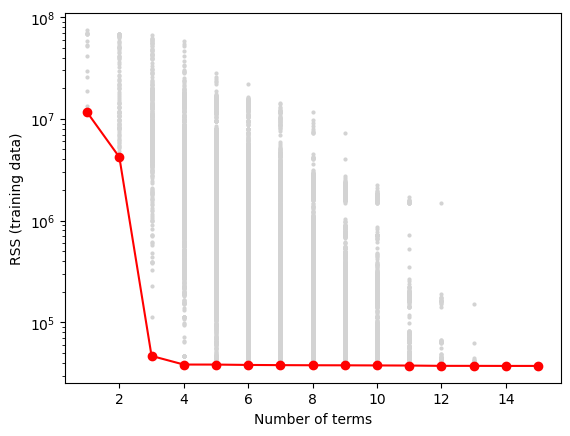

In [8]:
plt.scatter(results["n_terms"], results["rss"], s=4, color="lightgrey")
plt.plot(best["n_terms"], best["rss"], marker="o", color="red")
plt.yscale("log")
plt.xlabel("Number of terms")
plt.ylabel("RSS (training data)")
plt.show()

### Step 3. Selection the best model based on BIC and MSE

    n_terms           rss          bic                                                                                    features
0         1  1.159538e+07  3973.043716                                                                                     (n3Q0,)
1         2  4.203229e+06  3589.328791                                                                                (n2Q2, n3Q1)
2         3  4.673145e+04  1867.590141                                                                          (n0Q3, n2Q1, n3Q0)
3         4  3.844152e+04  1798.553512                                                                    (n0Q3, n1Q2, n2Q1, n3Q0)
4         5  3.842052e+04  1804.294305                                                              (n0Q3, n1Q0, n1Q2, n2Q1, n3Q0)
5         6  3.809866e+04  1807.014526                                                        (n0Q3, n1Q0, n1Q2, n2Q0, n2Q1, n3Q0)
6         7  3.793892e+04  1811.351768                                             

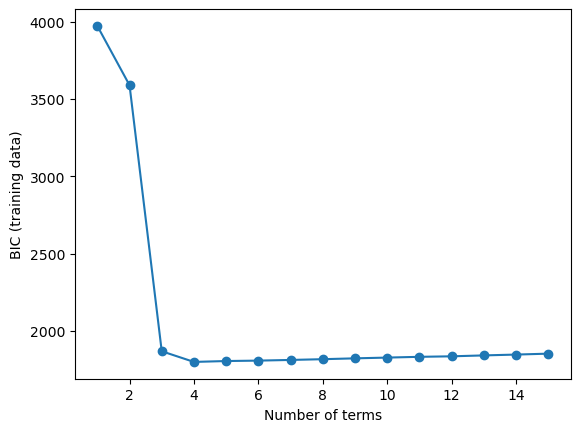

In [9]:
N = len(y_train)
best["bic"] = N * np.log(best["rss"] / N) + (best["n_terms"] + 1) * np.log(N)
chosen = best.loc[best["bic"].idxmin()]

print(best[["n_terms", "rss", "bic", "features"]].to_string())
print("Chosen:", chosen["n_terms"], "terms:", chosen["features"])

plt.plot(best["n_terms"], best["bic"], marker="o")
plt.xlabel("Number of terms")
plt.ylabel("BIC (training data)")
plt.show()

chosen_cols = list(chosen["features"])

In [10]:
val_mse = []
for cols in best["features"]:
    cols = list(cols)
    model = LinearRegression().fit(X_train[cols], y_train)
    val_mse.append(mean_squared_error(y_val, model.predict(X_val[cols])))
best["val_mse"] = val_mse


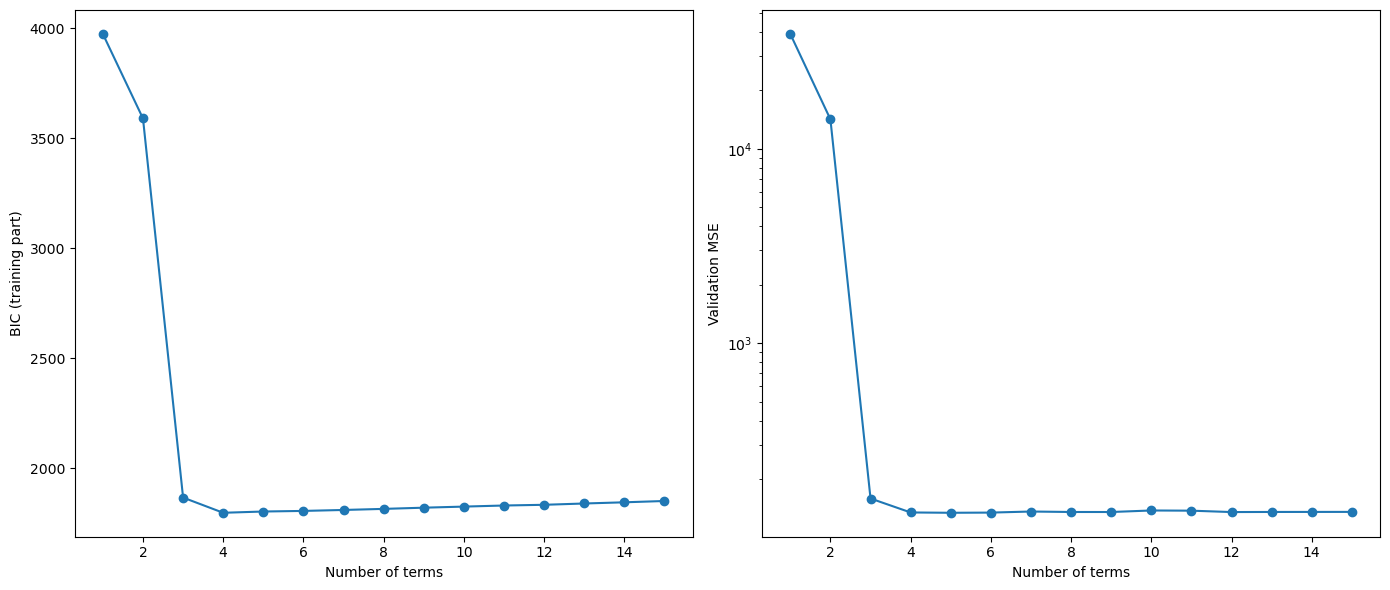

    n_terms           rss          bic       val_mse                                                                                    features
0         1  1.159538e+07  3973.043716  38940.342006                                                                                     (n3Q0,)
1         2  4.203229e+06  3589.328791  14172.282133                                                                                (n2Q2, n3Q1)
2         3  4.673145e+04  1867.590141    159.223267                                                                          (n0Q3, n2Q1, n3Q0)
3         4  3.844152e+04  1798.553512    134.977532                                                                    (n0Q3, n1Q2, n2Q1, n3Q0)
4         5  3.842052e+04  1804.294305    134.466685                                                              (n0Q3, n1Q0, n1Q2, n2Q1, n3Q0)
5         6  3.809866e+04  1807.014526    134.759012                                                        (n0Q3, n1Q0, n1Q2, n2Q

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].plot(best["n_terms"], best["bic"], marker="o")
axes[0].set_ylabel("BIC (training part)")
axes[1].plot(best["n_terms"], best["val_mse"], marker="o")
axes[1].set_yscale("log")
axes[1].set_ylabel("Validation MSE")
for ax in axes:
    ax.set_xlabel("Number of terms")
plt.tight_layout()
plt.show()

print(best[["n_terms", "rss", "bic", "val_mse", "features"]].to_string())
print("BIC chooses:           ", best.loc[best["bic"].idxmin(), "n_terms"])
print("Validation MSE chooses:", best.loc[best["val_mse"].idxmin(), "n_terms"])

chosen = best.loc[best["bic"].idxmin()]
chosen_cols = list(chosen["features"])

P = 40.6343 - 0.0083·n0Q3 - 0.0508·n1Q2 + 2.4113·n2Q1 + 7.6532·n3Q0
Test MSE: 106.76042728768189
Test R²:  0.9996311618125623


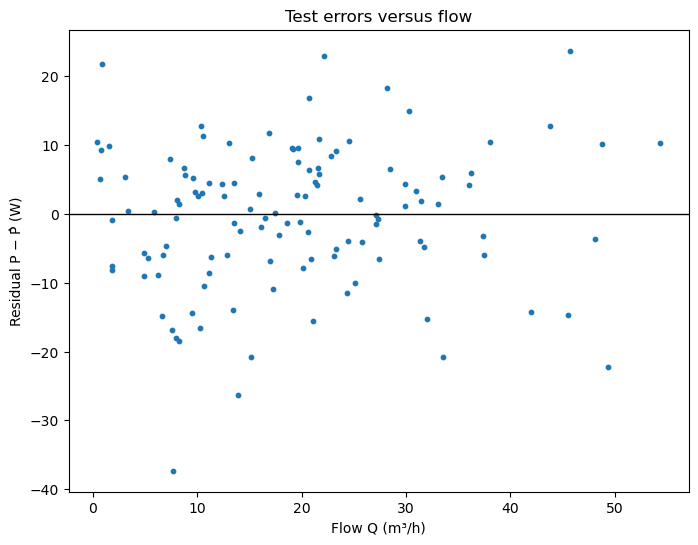

In [13]:
final_model = LinearRegression()
final_model.fit(X_train[chosen_cols], y_train)

expr = "P = " + str(round(final_model.intercept_, 4))
for name, coef in zip(chosen_cols, final_model.coef_):
    sign = " + " if coef >= 0 else " - "
    expr += sign + str(abs(round(coef, 4))) + "·" + name
print(expr)

# Test errors
y_pred = final_model.predict(X_test[chosen_cols])
residuals = y_test.to_numpy() - y_pred
print("Test MSE:", mean_squared_error(y_test, y_pred))
print("Test R²: ", final_model.score(X_test[chosen_cols], y_test))

# Errors versus flow
plt.figure(figsize=(8, 6))
plt.scatter(test["Q"], residuals, s=10)
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Flow Q (m³/h)")
plt.ylabel("Residual P − P̂ (W)")
plt.title("Test errors versus flow")
plt.show()

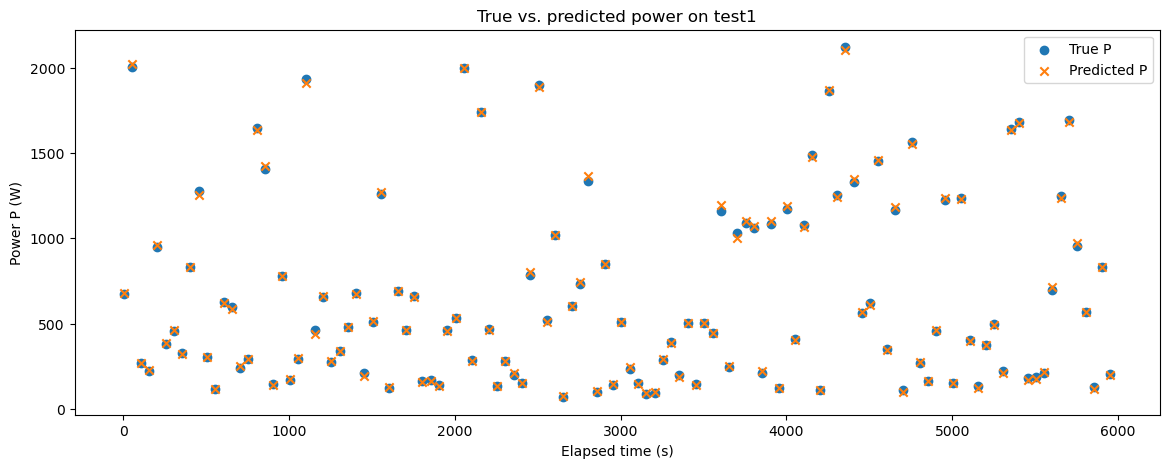

In [ ]:
order = np.argsort(test["elapsed_s"].to_numpy())
t = test["elapsed_s"].to_numpy()[order]

plt.figure(figsize=(14, 5))
plt.scatter(t, y_test.to_numpy()[order], marker="o",  label="True P")
plt.scatter(t, y_pred[order], marker="x",label="Predicted P")
plt.xlabel("Elapsed time (s)")
plt.ylabel("Power P (W)")
plt.title("True vs. predicted power on test1")
plt.legend()
plt.show()